TASK 04

In [1]:
# Cell 1 — imports and settings
from pathlib import Path
import math
import csv
import cv2
import numpy as np
import matplotlib.pyplot as plt

IMAGE_PATH = Path("data") / "task03_objects.jpg"
MASK_PATH = Path("results") / "task03_final_mask.png"      # output of Task 3
RESULTS_DIR = Path("results")
TARGET_WIDTH = 800
MIN_AREA = 300                                              # same rule as Task 3
print("OpenCV version:", cv2.__version__)

OpenCV version: 5.0.0


— load mask + colour image (same size), find contours

Mask: (600, 800) values: [  0 255]
RETR_EXTERNAL: 16 contours
RETR_CCOMP:    18 contours (2 of them are holes)
Objects after filtering: 9 (expected 9)


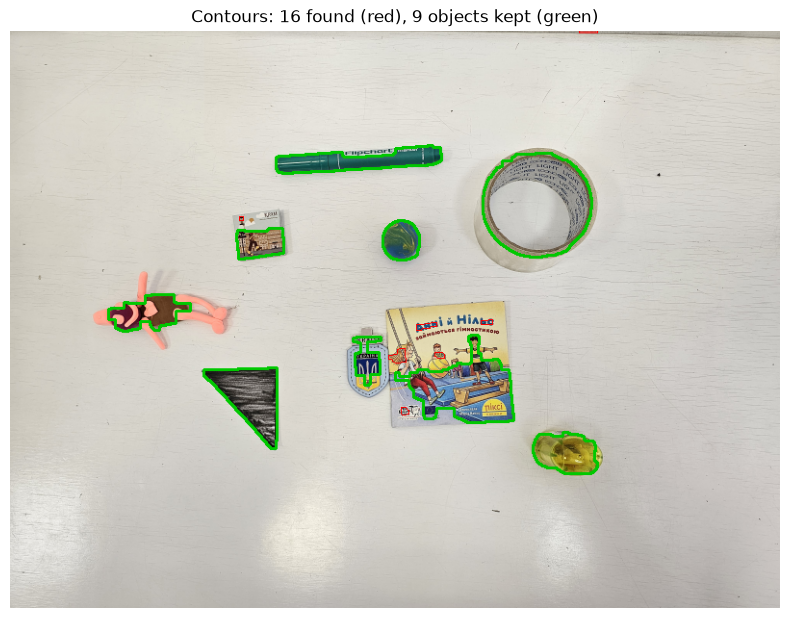

In [2]:
# Cell 2 
mask = cv2.imread(str(MASK_PATH), cv2.IMREAD_GRAYSCALE)
image = cv2.imread(str(IMAGE_PATH), cv2.IMREAD_COLOR)
if mask is None or image is None:
    raise FileNotFoundError("Check MASK_PATH and IMAGE_PATH")

# exporting dimention of the image 
h, w = image.shape[:2]
# resizing the image for better visualization and processing, keeping the aspect ratio
resized = cv2.resize(image, (TARGET_WIDTH, round(h * TARGET_WIDTH / w)), interpolation=cv2.INTER_AREA)
assert resized.shape[:2] == mask.shape, f"size mismatch: {resized.shape[:2]} vs {mask.shape}"
print("Mask:", mask.shape, "values:", np.unique(mask))

# two retrieval modes: outer outlines only vs outlines + holes
cont_ext, hier_ext = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
cont_cc, hier_cc = cv2.findContours(mask, cv2.RETR_CCOMP, cv2.CHAIN_APPROX_SIMPLE)
n_holes = int((hier_cc[0][:, 3] >= 0).sum())          # contours that have a parent = holes
print(f"RETR_EXTERNAL: {len(cont_ext)} contours")
print(f"RETR_CCOMP:    {len(cont_cc)} contours ({n_holes} of them are holes)")

# keep real objects: area >= MIN_AREA and not touching the border
H, W = mask.shape
def is_object(c):
    x, y, bw, bh = cv2.boundingRect(c)
    return cv2.contourArea(c) >= MIN_AREA and not (x == 0 or y == 0 or x + bw >= W or y + bh >= H)

contours = [c for c in cont_ext if is_object(c)]
contours.sort(key=lambda c: (cv2.boundingRect(c)[1] // 100, cv2.boundingRect(c)[0]))   # stable order
print(f"Objects after filtering: {len(contours)} (expected 9)")

vis = resized.copy()
cv2.drawContours(vis, cont_ext, -1, (0, 0, 255), 1)       # all contours: thin red
cv2.drawContours(vis, contours, -1, (0, 200, 0), 2)       # kept objects: green
plt.figure(figsize=(10, 7.5))
plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
plt.title(f"Contours: {len(cont_ext)} found (red), {len(contours)} objects kept (green)")
plt.axis("off")
plt.savefig(RESULTS_DIR / "task04_step1_contours.png", dpi=150, bbox_inches="tight")
plt.show()

area, perimeter, bounding box, centre of mass, aspect ratio, vertices

 #    area   perim    x    y    w    h     cx     cy   w/h vert
 1    2876   389.2  276  119  173   30  361.4  134.9  5.77    5
 2    1267   133.4  387  197   39   42  406.3  218.0  0.93    8
 3    9684   374.6  491  127  114  109  547.1  180.6  1.05    8
 4    1976   246.7  102  274   86   39  142.9  292.9  2.21   14
 5    1304   155.2  235  205   50   33  259.4  220.5  1.52    4
 6    3536   277.8  201  350   77   85  250.4  380.6  0.91    3
 7     871   186.6  356  318   30   51  370.5  341.4  0.59   14
 8    5708   440.0  400  316  124   92  473.4  372.7  1.35    9
 9    2268   198.5  543  417   68   44  577.2  438.9  1.55    8


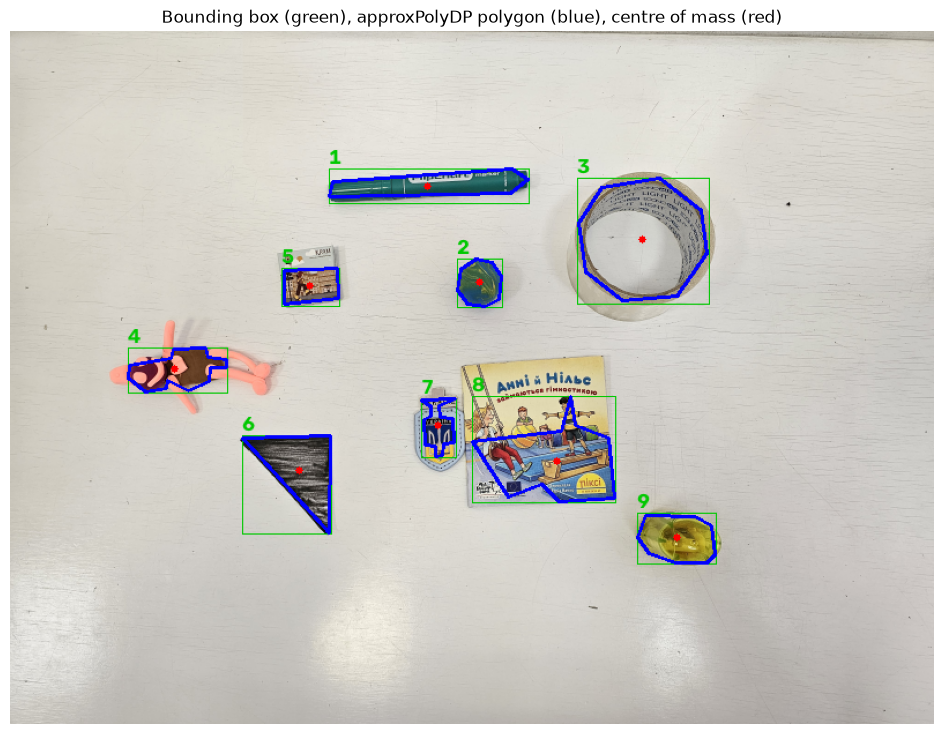

Object #3: contour area 9684 px² vs object pixels 5228 → contains a hole


In [3]:
# Cell 3 — area, perimeter, bounding box, centre of mass, aspect ratio, vertices
EPS = 0.02                                       # approxPolyDP tolerance = 2% of perimeter

rows = []
vis = resized.copy()
print(f"{'#':>2}{'area':>8}{'perim':>8}{'x':>5}{'y':>5}{'w':>5}{'h':>5}{'cx':>7}{'cy':>7}{'w/h':>6}{'vert':>5}")
for i, c in enumerate(contours, start=1):
    area = cv2.contourArea(c)
    perim = cv2.arcLength(c, True)
    x, y, bw, bh = cv2.boundingRect(c)
    M = cv2.moments(c)
    if M["m00"] == 0:                            # degenerate contour: avoid division by zero
        continue
    cx, cy = M["m10"] / M["m00"], M["m01"] / M["m00"]
    aspect = bw / bh
    approx = cv2.approxPolyDP(c, EPS * perim, True)
    n_vert = len(approx)

    rows.append([i, round(area), round(perim, 1), x, y, bw, bh,
                 round(cx, 1), round(cy, 1), round(aspect, 2), n_vert])
    print(f"{i:>2}{area:>8.0f}{perim:>8.1f}{x:>5}{y:>5}{bw:>5}{bh:>5}{cx:>7.1f}{cy:>7.1f}{aspect:>6.2f}{n_vert:>5}")

    cv2.rectangle(vis, (x, y), (x + bw, y + bh), (0, 200, 0), 1)       # bounding box
    cv2.drawContours(vis, [approx], -1, (255, 0, 0), 2)                # simplified polygon (blue)
    cv2.circle(vis, (int(cx), int(cy)), 3, (0, 0, 255), -1)            # centre of mass (red dot)
    cv2.putText(vis, str(i), (x, max(y - 4, 12)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 200, 0), 2)

with open(RESULTS_DIR / "task04_measurements.csv", "w", newline="", encoding="utf-8") as f:
    wr = csv.writer(f)
    wr.writerow(["id", "area_px2", "perimeter_px", "x", "y", "w", "h", "cx", "cy", "aspect_w_h", "vertices"])
    wr.writerows(rows)

plt.figure(figsize=(12, 9))
plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
plt.title("Bounding box (green), approxPolyDP polygon (blue), centre of mass (red)")
plt.axis("off")
plt.savefig(RESULTS_DIR / "task04_step2_measurements.png", dpi=150, bbox_inches="tight")
plt.show()

# contour area vs pixel count: the hole effect
pix_area = [cv2.countNonZero(cv2.drawContours(np.zeros_like(mask), [c], -1, 255, -1) & mask) for c in contours]
for i, (c, pa) in enumerate(zip(contours, pix_area), start=1):
    ca = cv2.contourArea(c)
    if ca > 1.2 * pa:
        print(f"Object #{i}: contour area {ca:.0f} px² vs object pixels {pa} → contains a hole")

 # object       vert  circ  rotAR  rect  solid  class      expected   ok
 1 marker          5  0.24   8.27  0.80   0.84  rectangle  rectangle  ✓
 2 ball            8  0.89   1.08  0.81   0.98  circle     circle     ✓
 3 tape roll       8  0.87   1.05  0.79   0.99  circle     circle     ✓
 4 clay figure    14  0.41   2.30  0.62   0.80  undefined  undefined  ✓
 5 small box       4  0.68   1.62  0.88   0.94  rectangle  square     ✗
 6 triangle        3  0.58   1.11  0.55   0.96  triangle   triangle   ✓
 7 badge          14  0.31   1.72  0.60   0.71  undefined  polygon    ✗
 8 booklet         9  0.37   1.12  0.52   0.72  undefined  square     ✗
 9 sharpener       8  0.72   1.56  0.79   0.94  ellipse    ellipse    ✓

Correctly classified: 6 of 9


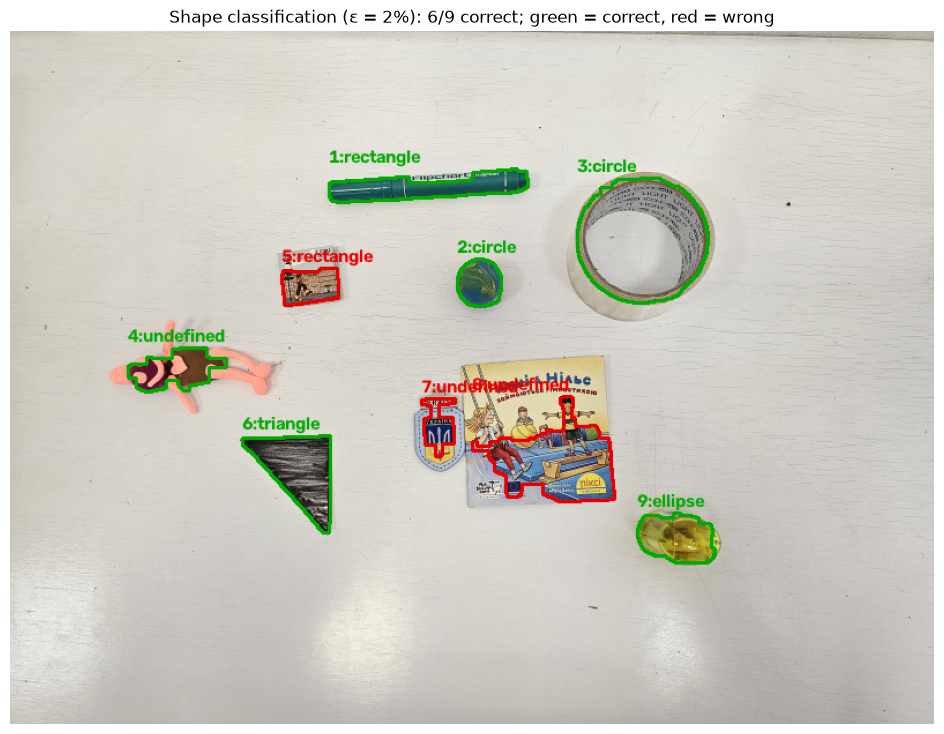


--- approxPolyDP tolerance experiment ---
  eps |  marker    ball  tape r  clay f  small   triang   badge  bookle  sharpe | correct
   1% |      11      10      13      21       8       5      16      23      14 | 5/9
   2% |       5       8       8      14       4       3      14       9       8 | 6/9
   4% |       2       8       8       4       4       3       5       5       5 | 4/9


In [4]:
# Cell 4 — Step 3: shape classification + epsilon experiment
EXPECTED = {1: "rectangle", 2: "circle", 3: "circle", 4: "undefined", 5: "square",
            6: "triangle", 7: "polygon", 8: "square", 9: "ellipse"}     # ground truth, by object number
OBJECT_NAMES = {1: "marker", 2: "ball", 3: "tape roll", 4: "clay figure", 5: "small box",
                6: "triangle", 7: "badge", 8: "booklet", 9: "sharpener"}

def shape_features(c, eps=EPS):
    area = cv2.contourArea(c)
    perim = cv2.arcLength(c, True)
    vert = len(cv2.approxPolyDP(c, eps * perim, True))
    circularity = 4 * math.pi * area / perim ** 2
    (_, _), (rw, rh), _ = cv2.minAreaRect(c)
    rot_ratio = max(rw, rh) / max(min(rw, rh), 1e-6)
    rectangularity = area / max(rw * rh, 1e-6)
    solidity = area / max(cv2.contourArea(cv2.convexHull(c)), 1e-6)
    return dict(vert=vert, circ=circularity, rot_ratio=rot_ratio, rect=rectangularity, solid=solidity)

def classify(f):
    if f["vert"] == 3:
        return "triangle"
    if f["circ"] >= 0.70 and f["vert"] >= 6:
        return "circle" if f["rot_ratio"] <= 1.15 else "ellipse"
    if f["vert"] == 4 or f["rect"] >= 0.78:
        return "square" if f["rot_ratio"] <= 1.15 else "rectangle"
    if 5 <= f["vert"] <= 8 and f["solid"] >= 0.90:
        return "polygon"
    return "undefined"

# --- main result (EPS = 0.02) ---
class_rows = []
vis = resized.copy()
print(f"{'#':>2} {'object':<12}{'vert':>5}{'circ':>6}{'rotAR':>7}{'rect':>6}{'solid':>7}  {'class':<11}{'expected':<11}ok")
for i, c in enumerate(contours, start=1):
    f = shape_features(c)
    cls = classify(f)
    ok = cls == EXPECTED[i]
    class_rows.append([i, OBJECT_NAMES[i], f["vert"], round(f["circ"], 2), round(f["rot_ratio"], 2),
                       round(f["rect"], 2), round(f["solid"], 2), cls, EXPECTED[i], ok])
    print(f"{i:>2} {OBJECT_NAMES[i]:<12}{f['vert']:>5}{f['circ']:>6.2f}{f['rot_ratio']:>7.2f}"
          f"{f['rect']:>6.2f}{f['solid']:>7.2f}  {cls:<11}{EXPECTED[i]:<11}{'✓' if ok else '✗'}")
    x, y, bw, bh = cv2.boundingRect(c)
    color = (0, 170, 0) if ok else (0, 0, 230)
    cv2.drawContours(vis, [c], -1, color, 2)
    cv2.putText(vis, f"{i}:{cls}", (x, max(y - 5, 12)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 2)
n_ok = sum(r[-1] for r in class_rows)
print(f"\nCorrectly classified: {n_ok} of {len(class_rows)}")

with open(RESULTS_DIR / "task04_classification.csv", "w", newline="", encoding="utf-8") as fcsv:
    wr = csv.writer(fcsv)
    wr.writerow(["id", "object", "vertices", "circularity", "rot_aspect", "rectangularity",
                 "solidity", "class", "expected", "correct"])
    wr.writerows(class_rows)

plt.figure(figsize=(12, 9))
plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
plt.title(f"Shape classification (ε = {EPS:.0%}): {n_ok}/{len(class_rows)} correct; green = correct, red = wrong")
plt.axis("off")
plt.savefig(RESULTS_DIR / "task04_step3_classification.png", dpi=150, bbox_inches="tight")
plt.show()

# --- epsilon experiment: effect of approxPolyDP tolerance ---
print("\n--- approxPolyDP tolerance experiment ---")
print(f"{'eps':>5} | " + " ".join(f"{OBJECT_NAMES[i][:6]:>7}" for i in range(1, 10)) + " | correct")
for eps in [0.01, 0.02, 0.04]:
    verts, n_corr = [], 0
    for i, c in enumerate(contours, start=1):
        f = shape_features(c, eps)
        verts.append(f["vert"])
        n_corr += classify(f) == EXPECTED[i]
    print(f"{eps:>5.0%} | " + " ".join(f"{v:>7}" for v in verts) + f" | {n_corr}/9")